<a href="https://colab.research.google.com/github/gpgovindapromod/aiml/blob/main/Randomforest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

df = pd.read_csv("mcu.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Saving mcu.csv to mcu.csv
Dataset loaded successfully!
Shape: (62, 10)


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape:
(62, 10)

Column Names:
['movie_title', 'mcu_phase', 'release_date', 'tomato_meter', 'audience_score', 'movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office']

Data Types:
movie_title              object
mcu_phase                object
release_date             object
tomato_meter              int64
audience_score            int64
movie_duration          float64
production_budget       float64
opening_weekend         float64
domestic_box_office     float64
worldwide_box_office    float64
dtype: object

First 5 Rows:


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0


In [ ]:
# Fill missing numerical values with median

numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())


# Fill missing categorical/text values with 'Unknown'

text_cols = df.select_dtypes(include=['object']).columns

for col in text_cols:
    df[col] = df[col].fillna('Unknown')


print(f"Rows after filling missing values: {len(df)}")
print("\nMissing values after preprocessing:")

print(df.isnull().sum())

Rows after filling missing values: 62

Missing values after preprocessing:
movie_title             0
mcu_phase               0
release_date            0
tomato_meter            0
audience_score          0
movie_duration          0
production_budget       0
opening_weekend         0
domestic_box_office     0
worldwide_box_office    0
dtype: int64


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (62, 10)

Columns:
['movie_title', 'mcu_phase', 'release_date', 'tomato_meter', 'audience_score', 'movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office']

Data Types:
movie_title              object
mcu_phase                object
release_date             object
tomato_meter              int64
audience_score            int64
movie_duration          float64
production_budget       float64
opening_weekend         float64
domestic_box_office     float64
worldwide_box_office    float64
dtype: object

First 5 rows:


,movie_title,mcu_phase,release_date,tomato_meter,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office
0,Iron Man,Phase 1,2008-05-02,94,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0
1,The Incredible Hulk,Phase 1,2008-06-13,67,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0
2,Iron Man 2,Phase 1,2010-05-07,72,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0
3,Thor,Phase 1,2011-05-06,77,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0
4,Captain America The First Avenger,Phase 1,2011-07-22,80,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0


In [ ]:
# Convert release_date to datetime

df['release_date'] = pd.to_datetime(
    df['release_date'],
    errors='coerce'
)

# Create useful date features

df['release_year'] = df['release_date'].dt.year
df['release_month'] = df['release_date'].dt.month

print(df[['release_date', 'release_year', 'release_month']].head())

  release_date  release_year  release_month
0   2008-05-02          2008              5
1   2008-06-13          2008              6
2   2010-05-07          2010              5
3   2011-05-06          2011              5
4   2011-07-22          2011              7


In [ ]:
df['tomato_class'] = pd.cut(
    df['tomato_meter'],
    bins=[-1, 59, 79, 100],
    labels=['Low', 'Medium', 'High']
)

print("Classification target:")
print(df['tomato_class'].value_counts())

Classification target:
tomato_class
High      42
Medium    16
Low        4
Name: count, dtype: int64


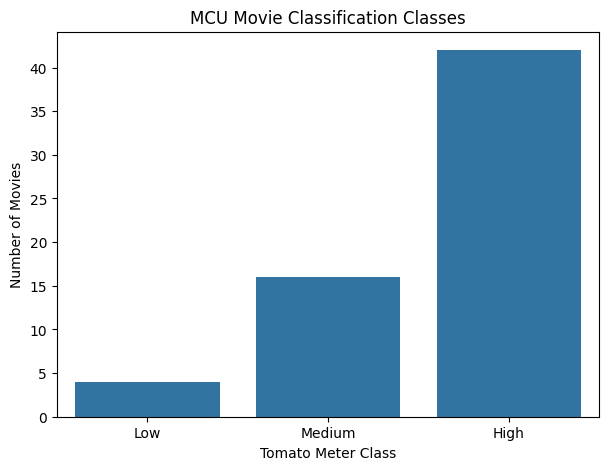

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='tomato_class'
)

plt.xlabel("Tomato Meter Class")
plt.ylabel("Number of Movies")
plt.title("MCU Movie Classification Classes")

plt.show()

In [ ]:
features = [
    'mcu_phase',
    'audience_score',
    'movie_duration',
    'production_budget',
    'opening_weekend',
    'domestic_box_office',
    'worldwide_box_office',
    'release_year',
    'release_month'
]

X = df[features]

y = df['tomato_class']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['mcu_phase', 'audience_score', 'movie_duration', 'production_budget', 'opening_weekend', 'domestic_box_office', 'worldwide_box_office', 'release_year', 'release_month']

Target:
tomato_class


In [ ]:
X = pd.get_dummies(
    X,
    columns=['mcu_phase'],
    drop_first=True
)

print("Shape after encoding:", X.shape)

display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Shape after encoding: (62, 13)


,audience_score,movie_duration,production_budget,opening_weekend,domestic_box_office,worldwide_box_office,release_year,release_month,mcu_phase_Phase 2,mcu_phase_Phase 3,mcu_phase_Phase 4,mcu_phase_Phase 5,mcu_phase_Phase 6
0,91,126.0,140000000.0,102118668.0,319034126.0,585796247.0,2008,5,False,False,False,False,False
1,70,112.0,137500000.0,55414050.0,134806913.0,265573859.0,2008,6,False,False,False,False,False
2,71,124.0,200000000.0,128122480.0,312433331.0,621156389.0,2010,5,False,False,False,False,False
3,76,114.0,150000000.0,65723338.0,181030624.0,449326618.0,2011,5,False,False,False,False,False
4,75,124.0,140000000.0,65058524.0,176654505.0,370569774.0,2011,7,False,False,False,False,False


Training samples: 49
Testing samples: 13


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print(rf_model)
rf_model.fit(
    X_train,
    y_train
)

print("Random Forest Classification model trained successfully!")

RandomForestClassifier(n_jobs=-1, random_state=42)
Random Forest Classification model trained successfully!


Actual values:
['High', 'Medium', 'High', 'High', 'High', ..., 'High', 'Low', 'High', 'Medium', 'High']
Length: 13
Categories (3, object): ['Low' < 'Medium' < 'High']

Predicted values:
['High' 'High' 'High' 'High' 'Medium' 'High' 'High' 'High' 'High' 'Medium'
 'Low' 'High' 'Medium']
Accuracy: 0.46153846153846156
Accuracy (%): 46.15384615384615
Precision: 0.46153846153846156
Recall: 0.46153846153846156
F1 Score: 0.46153846153846156
RANDOM FOREST CLASSIFICATION RESULTS
Accuracy  : 0.4615
Precision : 0.4615
Recall    : 0.4615
F1 Score  : 0.4615
Confusion Matrix:
[[6 1 2]
 [0 0 1]
 [3 0 0]]


,Feature,Importance
0,audience_score,0.351042
1,movie_duration,0.101328
6,release_year,0.098674
7,release_month,0.091729
4,domestic_box_office,0.090576
5,worldwide_box_office,0.080880
3,opening_weekend,0.058808
2,production_budget,0.058644
11,mcu_phase_Phase 5,0.038155
10,mcu_phase_Phase 4,0.009631


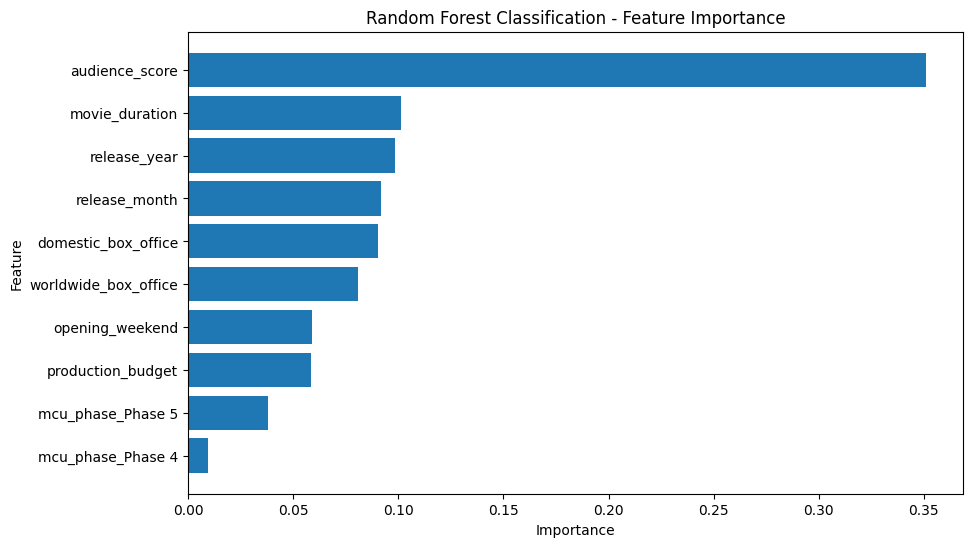

,Metric,Score
0,Accuracy,0.461538
1,Precision,0.461538
2,Recall,0.461538
3,F1 Score,0.461538


In [ ]:
y_pred = rf_model.predict(X_test)

print("Actual values:")
print(y_test.values)

print("\nPredicted values:")
print(y_pred)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("Precision:", precision)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("Recall:", recall)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

print("F1 Score:", f1)

print("=" * 50)
print("RANDOM FOREST CLASSIFICATION RESULTS")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Classification - Feature Importance")

plt.show()

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Score': [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(results)